# 14F — Capped Portfolio Risk and Theme Analysis

This notebook applies the same diagnostics used for the uncapped seeded-embedding portfolio to the earlier **frozen capped portfolios**. It does not refit, reselect, download data, or call an API.

Two designs are kept separate:

1. The daily, three-month frozen portfolios from the long–short, hybrid, and consensus experiments are used for Sharpe ratios, volatility, benchmark correlations, information ratios, and factor regressions.
2. The earlier matched-cardinality long-only experiment is shown separately using its saved endpoint returns. Its longer evaluation design is not silently combined with the daily three-month panel.

All portfolio definitions were frozen before these return diagnostics were calculated.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

ROOT = Path.cwd()
if ROOT.name != 'sp500_critical_minerals':
    candidate = Path('/Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals')
    if candidate.exists(): ROOT = candidate

ATTR = ROOT / 'factor_attribution_v1'
FORWARD = ROOT / 'forward_performance_v1'
OUT = ROOT / 'capped_portfolio_analysis_v1'
FIG = OUT / 'figures'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

daily = pd.read_parquet(ATTR / 'daily_attribution_panel.parquet')
daily['date'] = pd.to_datetime(daily['date'])
assert daily.groupby('method').size().nunique() == 1
assert daily.groupby('method').date.nunique().min() == 248
print('Methods:', sorted(daily.method.unique()))
print('Dates:', daily.date.min().date(), 'to', daily.date.max().date())

Methods: ['consensus', 'embedding', 'hybrid', 'hybrid_long_only', 'llm', 'matched_text']
Dates: 2024-06-03 to 2025-06-30


## 1. Construct a common calendar-time return panel

The six capped methods are evaluated on the same 248 trading dates. `hybrid_long_only` is a funded long-only portfolio. The other five methods are self-financing long–short spreads.

In [11]:
method_returns = daily.pivot(index='date', columns='method', values='portfolio_return').sort_index()
bench = (daily.sort_values(['date','method']).drop_duplicates('date')
         .set_index('date')[['market_return','broad_cm_equity_return','broad_cm_equity_ex_market','RF','Mkt-RF','SMB','HML','RMW','CMA','Mom']])
panel = method_returns.join(bench, how='inner')
panel.to_parquet(OUT / 'capped_daily_return_panel.parquet')
display(panel.head())
print('Complete rows:', int(panel.notna().all(axis=1).sum()), '/', len(panel))

,consensus,embedding,hybrid,hybrid_long_only,llm,matched_text,market_return,broad_cm_equity_return,broad_cm_equity_ex_market,RF,Mkt-RF,SMB,HML,RMW,CMA,Mom
date,,,,,,,,,,,,,,,,
2024-06-03,-0.009240,0.010800,-0.006948,-0.008334,-0.010331,-0.010294,0.000815,-0.004693,-0.005509,0.0002,0.0005,-0.0031,-0.0057,0.0039,-0.0044,-0.0019
2024-06-04,-0.021475,0.000821,-0.004858,-0.007023,-0.007858,-0.026267,0.001118,-0.021330,-0.022448,0.0002,-0.0006,-0.0128,-0.0076,-0.0022,-0.0012,-0.0020
2024-06-05,0.009818,0.002421,0.002707,0.007065,0.004536,0.007741,0.011885,0.011675,-0.000210,0.0002,0.0123,0.0032,-0.0061,-0.0044,-0.0068,0.0115
2024-06-06,0.005577,-0.007420,0.003916,-0.004191,0.001823,0.011222,-0.000018,0.002566,0.002584,0.0002,-0.0006,-0.0057,-0.0007,-0.0002,-0.0017,-0.0055
2024-06-07,-0.012037,0.001568,-0.011630,-0.011900,-0.018184,-0.015751,-0.001216,-0.032162,-0.030946,0.0002,-0.0023,-0.0095,0.0007,0.0033,0.0018,0.0010


Complete rows: 248 / 248


## 2. Visualize the capped portfolios

Long-only and long–short strategies are shown separately because a funded equity portfolio and a zero-investment spread have different economic interpretations.

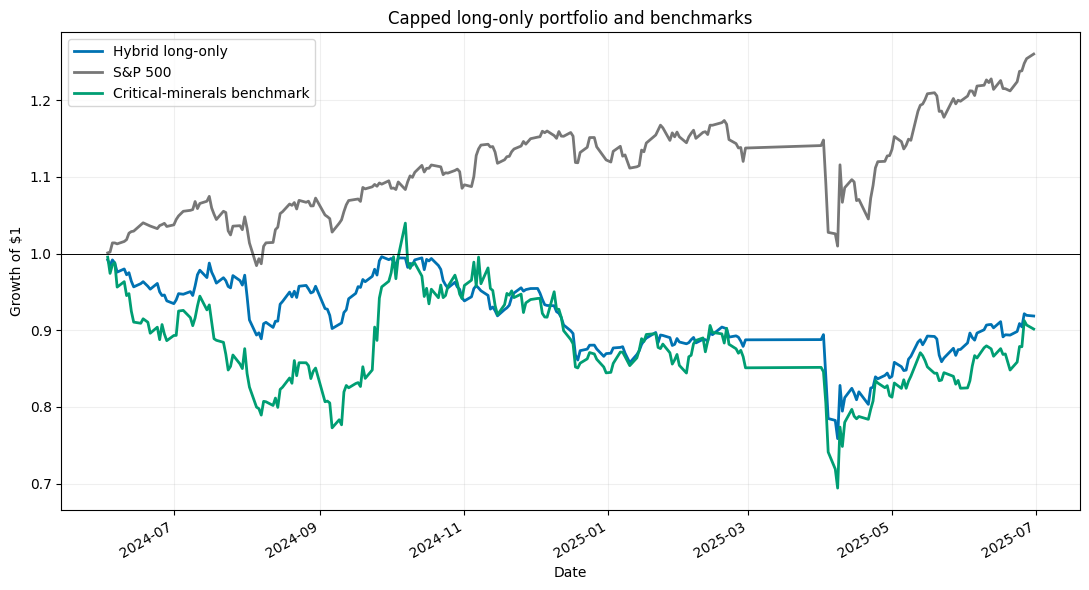

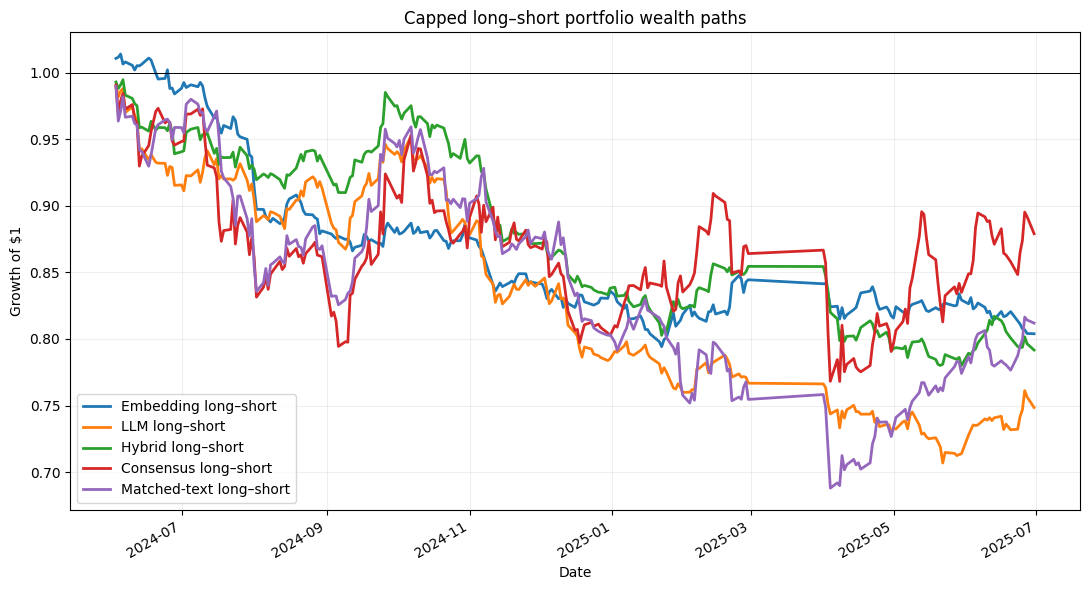

In [12]:
labels = {
    'consensus':'Consensus long–short', 'embedding':'Embedding long–short',
    'hybrid':'Hybrid long–short', 'hybrid_long_only':'Hybrid long-only',
    'llm':'LLM long–short', 'matched_text':'Matched-text long–short',
    'market_return':'S&P 500', 'broad_cm_equity_return':'Critical-minerals benchmark'
}

wealth_lo = (1 + panel[['hybrid_long_only','market_return','broad_cm_equity_return']]).cumprod().rename(columns=labels)
ax = wealth_lo.plot(figsize=(11,6), linewidth=2, color=['#0072B2','#777777','#009E73'])
ax.axhline(1,color='black',lw=.7); ax.grid(alpha=.2)
ax.set(title='Capped long-only portfolio and benchmarks', xlabel='Date', ylabel='Growth of $1')
plt.tight_layout(); plt.savefig(FIG/'capped_long_only_vs_benchmarks.png',dpi=180,bbox_inches='tight'); plt.show()

ls = ['embedding','llm','hybrid','consensus','matched_text']
wealth_ls = (1 + panel[ls]).cumprod().rename(columns=labels)
ax = wealth_ls.plot(figsize=(11,6), linewidth=2)
ax.axhline(1,color='black',lw=.7); ax.grid(alpha=.2)
ax.set(title='Capped long–short portfolio wealth paths', xlabel='Date', ylabel='Growth of $1')
plt.tight_layout(); plt.savefig(FIG/'capped_long_short_wealth.png',dpi=180,bbox_inches='tight'); plt.show()

## 3. Risk and Sharpe-ratio comparison

The conventional Sharpe ratio uses excess returns over the daily risk-free rate for funded long-only investments. Long–short spreads are already self-financing, so their spread return is used directly.

In [13]:
def stats(raw, sharpe_series):
    raw=raw.dropna(); s=sharpe_series.loc[raw.index].dropna(); raw=raw.loc[s.index]
    wealth=(1+raw).cumprod()
    return pd.Series({
        'days':len(raw), 'cumulative_return':wealth.iloc[-1]-1,
        'annualized_mean':raw.mean()*252,
        'annualized_volatility':raw.std(ddof=1)*np.sqrt(252),
        'conventional_sharpe':s.mean()/s.std(ddof=1)*np.sqrt(252),
        'maximum_drawdown':(wealth/wealth.cummax()-1).min()
    })

rows=[]
for method in ls:
    x=stats(panel[method],panel[method]); x['portfolio']=method; x['portfolio_type']='self_financing_long_short'; rows.append(x)
for method,raw in [('hybrid_long_only',panel.hybrid_long_only),('sp500',panel.market_return),('critical_minerals',panel.broad_cm_equity_return)]:
    x=stats(raw,raw-panel.RF); x['portfolio']=method; x['portfolio_type']='funded_long_only'; rows.append(x)
performance=pd.DataFrame(rows)[['portfolio','portfolio_type','days','cumulative_return','annualized_mean','annualized_volatility','conventional_sharpe','maximum_drawdown']]
performance.to_parquet(OUT/'capped_performance_summary.parquet',index=False)
display(performance.round(4))

,portfolio,portfolio_type,days,cumulative_return,annualized_mean,annualized_volatility,conventional_sharpe,maximum_drawdown
0,embedding,self_financing_long_short,248.0,-0.1961,-0.2170,0.0974,-2.2284,-0.2168
1,llm,self_financing_long_short,248.0,-0.2515,-0.2853,0.1336,-2.1358,-0.2858
2,hybrid,self_financing_long_short,248.0,-0.2083,-0.2309,0.1134,-2.0355,-0.2159
3,consensus,self_financing_long_short,248.0,-0.1209,-0.0976,0.2583,-0.3778,-0.2248
4,matched_text,self_financing_long_short,248.0,-0.1880,-0.1903,0.2063,-0.9225,-0.3049
5,hybrid_long_only,funded_long_only,248.0,-0.0815,-0.0648,0.2081,-0.5539,-0.2383
6,sp500,funded_long_only,248.0,0.2602,0.2544,0.1980,1.0306,-0.1396
7,critical_minerals,funded_long_only,248.0,-0.0985,-0.0536,0.3238,-0.3211,-0.3324


## 4. Benchmark-relative performance

The information ratio is the annualized active return relative to the critical-minerals benchmark divided by tracking error. Its cleanest interpretation is for the capped long-only portfolio because both sides are funded long-only investments.

In [14]:
ir_rows=[]
for method in ['hybrid_long_only']:
    for benchmark in ['broad_cm_equity_return','market_return']:
        active=panel[method]-panel[benchmark]
        ir_rows.append({'portfolio':method,'benchmark':benchmark,
                        'annualized_active_return':active.mean()*252,
                        'tracking_error':active.std(ddof=1)*np.sqrt(252),
                        'information_ratio':active.mean()/active.std(ddof=1)*np.sqrt(252),
                        'correlation':panel[method].corr(panel[benchmark]),
                        'simple_beta':panel[method].cov(panel[benchmark])/panel[benchmark].var()})
relative=pd.DataFrame(ir_rows)
relative.to_parquet(OUT/'capped_long_only_relative_performance.parquet',index=False)
display(relative.round(4))

,portfolio,benchmark,annualized_active_return,tracking_error,information_ratio,correlation,simple_beta
0,hybrid_long_only,broad_cm_equity_return,-0.0113,0.2182,-0.0517,0.7461,0.4795
1,hybrid_long_only,market_return,-0.3193,0.1118,-2.8549,0.8494,0.8928


## 5. Does the capped portfolio preserve critical-minerals exposure?

For long-only, the dependent variable is portfolio return minus the risk-free rate. For long–short portfolios, it is the self-financing spread return. HAC standard errors use five lags. The key result is the minerals-factor beta and the increase in R² when the minerals factor is added.

In [15]:
factor_rows=[]
methods=ls+['hybrid_long_only']
for method in methods:
    y=panel[method] if method in ls else panel[method]-panel.RF
    specifications={
        'market':['Mkt-RF'],
        'market_plus_cm':['Mkt-RF','broad_cm_equity_ex_market'],
        'ff5_mom':['Mkt-RF','SMB','HML','RMW','CMA','Mom'],
        'ff5_mom_plus_cm':['Mkt-RF','SMB','HML','RMW','CMA','Mom','broad_cm_equity_ex_market']
    }
    fitted={}
    for spec,cols in specifications.items():
        z=pd.concat([y.rename('y'),panel[cols]],axis=1).dropna()
        model=sm.OLS(z.y,sm.add_constant(z[cols])).fit(cov_type='HAC',cov_kwds={'maxlags':5})
        fitted[spec]=model
        factor_rows.append({'method':method,'specification':spec,'n':int(model.nobs),
                            'r2':model.rsquared,'adjusted_r2':model.rsquared_adj,
                            'annualized_alpha':model.params['const']*252,
                            'alpha_t':model.tvalues['const'],
                            'cm_beta':model.params.get('broad_cm_equity_ex_market',np.nan),
                            'cm_t':model.tvalues.get('broad_cm_equity_ex_market',np.nan),
                            'cm_p':model.pvalues.get('broad_cm_equity_ex_market',np.nan)})
    factor_rows[-3]['incremental_cm_r2_vs_market']=fitted['market_plus_cm'].rsquared-fitted['market'].rsquared
    factor_rows[-1]['incremental_cm_r2_vs_ff5_mom']=fitted['ff5_mom_plus_cm'].rsquared-fitted['ff5_mom'].rsquared

factor_results=pd.DataFrame(factor_rows)
factor_results.to_parquet(OUT/'capped_factor_and_theme_exposure.parquet',index=False)
focus=factor_results[factor_results.specification.eq('ff5_mom_plus_cm')][['method','annualized_alpha','alpha_t','cm_beta','cm_t','cm_p','r2','incremental_cm_r2_vs_ff5_mom']]
display(focus.round(4))

,method,annualized_alpha,alpha_t,cm_beta,cm_t,cm_p,r2,incremental_cm_r2_vs_ff5_mom
3,embedding,-0.2157,-2.0336,0.0214,0.9204,0.3574,0.1202,0.0028
7,llm,-0.2193,-2.2314,0.3019,13.2213,0.0000,0.4821,0.2936
11,hybrid,-0.1825,-1.8886,0.2143,8.6736,0.0000,0.3125,0.2052
15,consensus,-0.1019,-0.5625,0.4848,9.7759,0.0000,0.5144,0.2024
19,matched_text,-0.1825,-1.2738,0.3745,6.8529,0.0000,0.4225,0.1894
23,hybrid_long_only,-0.2126,-3.0177,0.1885,10.3934,0.0000,0.8667,0.0471


## 6. Volatility-matched capped long-only comparison

The capped long-only portfolio is levered or de-levered to the minerals benchmark's realized volatility. Financing is charged at the contemporaneous risk-free rate. This is a descriptive, ex-post risk-matching diagnostic—not an investable rule selected before the sample.

In [16]:
lo_vol=panel.hybrid_long_only.std(ddof=1)*np.sqrt(252)
cm_vol=panel.broad_cm_equity_return.std(ddof=1)*np.sqrt(252)
leverage=cm_vol/lo_vol
scaled=panel.RF+leverage*(panel.hybrid_long_only-panel.RF)
vm=pd.DataFrame([
    {'portfolio':'capped_hybrid_long_only','leverage':1.0,**stats(panel.hybrid_long_only,panel.hybrid_long_only-panel.RF).to_dict()},
    {'portfolio':'capped_hybrid_long_only_vol_matched','leverage':leverage,**stats(scaled,scaled-panel.RF).to_dict()},
    {'portfolio':'critical_minerals','leverage':1.0,**stats(panel.broad_cm_equity_return,panel.broad_cm_equity_return-panel.RF).to_dict()}
])
vm.to_parquet(OUT/'capped_volatility_matched_comparison.parquet',index=False)
display(vm.round(4))

,portfolio,leverage,days,cumulative_return,annualized_mean,annualized_volatility,conventional_sharpe,maximum_drawdown
0,capped_hybrid_long_only,1.0000,248.0,-0.0815,-0.0648,0.2081,-0.5539,-0.2383
1,capped_hybrid_long_only_vol_matched,1.5561,248.0,-0.1633,-0.1289,0.3238,-0.5539,-0.3623
2,critical_minerals,1.0000,248.0,-0.0985,-0.0536,0.3238,-0.3211,-0.3324


## 7. Earlier matched-cardinality long-only endpoints

These saved results compare equal-cardinality embedding-only and LLM-only portfolios. They are displayed separately because only endpoint returns—not a common daily path—were frozen in that stage.

,vintage,portfolio,selected_firms,portfolio_return,available_universe_adjusted_return
0,2024q1,embedding_only_primary,14.0,-0.0574,-0.1192
1,2024q1,llm_only_common_support,14.0,-0.0123,-0.074
2,2024q2,embedding_only_primary,13.0,0.0301,-0.0427
3,2024q2,llm_only_common_support,13.0,0.0316,-0.0412
4,2024q3,embedding_only_primary,15.0,-0.0179,0.0235
5,2024q3,llm_only_common_support,15.0,-0.1372,-0.0959
6,2024q4,embedding_only_primary,15.0,0.0303,-0.0249
7,2024q4,llm_only_common_support,15.0,0.0924,0.0372


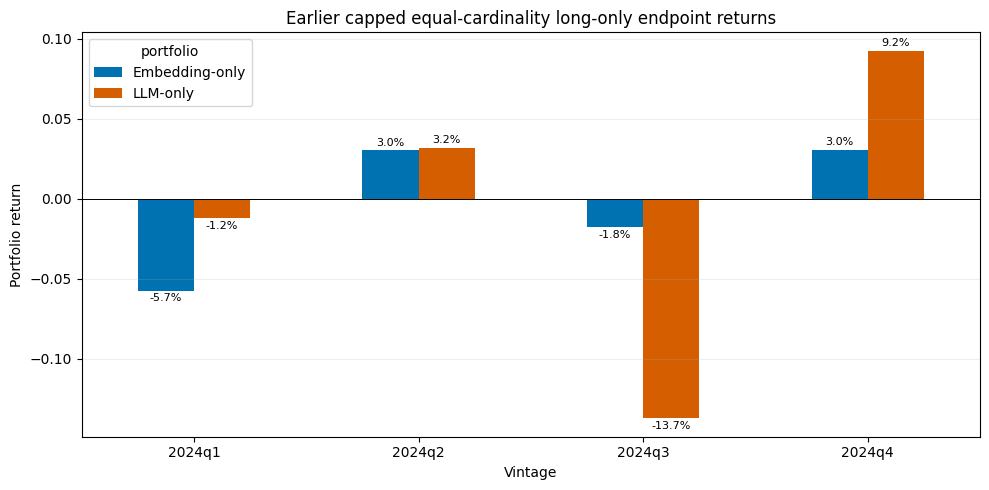

In [17]:
primary=pd.read_parquet(FORWARD/'primary_portfolio_results.parquet')
display(primary[['vintage','portfolio','selected_firms','portfolio_return','available_universe_adjusted_return']].round(4))
pivot=primary.pivot(index='vintage',columns='portfolio',values='portfolio_return')
ax=pivot.rename(columns={'embedding_only_primary':'Embedding-only','llm_only_common_support':'LLM-only'}).plot(kind='bar',figsize=(10,5),color=['#0072B2','#D55E00'])
ax.axhline(0,color='black',lw=.7); ax.set(title='Earlier capped equal-cardinality long-only endpoint returns',xlabel='Vintage',ylabel='Portfolio return'); ax.grid(axis='y',alpha=.2)
for container in ax.containers: ax.bar_label(container,fmt='%.1f%%',labels=[f'{100*v:.1f}%' for v in container.datavalues],padding=2,fontsize=8)
plt.xticks(rotation=0);plt.tight_layout();plt.savefig(FIG/'matched_cardinality_long_only_endpoints.png',dpi=180,bbox_inches='tight');plt.show()

## 8. Interpretation guide

- Sharpe ratio evaluates return above cash per unit of total risk; it does not use either benchmark.
- Information ratio evaluates active performance relative to a chosen benchmark.
- Correlation and simple beta show whether the capped long-only portfolio behaves more like the broad market or the minerals benchmark.
- The controlled minerals beta tests whether thematic exposure remains after standard equity factors are held constant.
- Incremental R² measures how much explanatory power the minerals factor adds.
- Volatility matching asks whether conclusions survive after equalizing realized risk; it must not be described as a pre-specified trading strategy.

Because there are only 248 trading observations across four short frozen windows, all statistical conclusions remain pilot evidence rather than definitive long-horizon performance claims.

In [18]:
required=[
    OUT/'capped_daily_return_panel.parquet', OUT/'capped_performance_summary.parquet',
    OUT/'capped_long_only_relative_performance.parquet', OUT/'capped_factor_and_theme_exposure.parquet',
    OUT/'capped_volatility_matched_comparison.parquet', FIG/'capped_long_only_vs_benchmarks.png',
    FIG/'capped_long_short_wealth.png', FIG/'matched_cardinality_long_only_endpoints.png']
gates=pd.DataFrame([
    {'gate':'six_capped_methods','value':daily.method.nunique(),'threshold':6,'passed':daily.method.nunique()==6},
    {'gate':'common_248_day_panel','value':len(panel),'threshold':248,'passed':len(panel)==248},
    {'gate':'all_outputs_saved','value':sum(p.exists() for p in required),'threshold':len(required),'passed':all(p.exists() for p in required)},
    {'gate':'no_selection_or_refit','value':True,'threshold':True,'passed':True}
])
# Keep descriptive gate values type-consistent for PyArrow serialization.
gates['value'] = gates['value'].astype(str)
gates['threshold'] = gates['threshold'].astype(str)
gates['passed'] = gates['passed'].astype(bool)
gates.to_parquet(OUT/'decision_gates.parquet',index=False)
display(gates)
assert gates.passed.all()
print('Saved analysis to:',OUT)

,gate,value,threshold,passed
0,six_capped_methods,6,6,True
1,common_248_day_panel,248,248,True
2,all_outputs_saved,8,8,True
3,no_selection_or_refit,True,True,True


Saved analysis to: /Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals/capped_portfolio_analysis_v1
